# BÁO CÁO THỰC HÀNH HỌC MÁY -- BÀI KIỂM TRA 1 (TUẦN 4)
## HỌC PHẦN: HỌC MÁY (MACHINE LEARNING) -- HỌC KỲ 1, NĂM HỌC 2026--2027
**Giảng viên hướng dẫn:** Nguyễn Tuấn Anh  
**Đề tài:** Ứng dụng học máy trong dự đoán tương tác thuốc--thuốc và khắc phục hiện tượng rò rỉ dữ liệu  
**Sinh viên thực hiện:**
1. Trần Đặng Vương Quốc Long -- **MSSV:** DTC235200472 -- **Lớp:** KHMT K22A  
2. Bùi Minh Ảnh -- **MSSV:** DTC235160004 -- **Lớp:** KHMT K22  

---
### NỘI DUNG ĐÁNH GIÁ THEO 10 TIÊU CHÍ BÀI KIỂM TRA 1:
1. **[N] Tiêu chí 1:** Phát biểu bài toán học máy (loại bài toán, đơn vị mẫu, đầu vào, đầu ra).
2. **[N] Tiêu chí 2:** Mục tiêu thực tế và tiêu chí thành công định lượng.
3. **[N] Tiêu chí 3:** Nguồn dữ liệu, quy mô và từ điển dữ liệu 10 kênh đặc trưng.
4. **[N] Tiêu chí 4:** Khảo sát thống kê mô tả, phân bố nhãn, bậc tương tác và độ tương đồng.
5. **[N] Tiêu chí 5:** Phân tích tương quan giữa các đặc trưng và tương quan với nhãn (3 nhận xét).
6. **[N] Tiêu chí 6:** Phát hiện và định lượng các vấn đề chất lượng dữ liệu (missing, ngoại lai, mất cân bằng, rò rỉ).
7. **[N] Tiêu chí 7:** Xử lý vấn đề chất lượng dữ liệu và so sánh dữ liệu trước -- sau.
8. **[N] Tiêu chí 8:** Chuẩn bị dữ liệu cho mô hình, thiết lập 4 kịch bản chia tập chống rò rỉ (Fit trên Train, Transform trên Test).
9. **[CN] Tiêu chí 9:** Lựa chọn và lý giải chiến lược đánh giá (Drug-disjoint) và hệ chỉ số (ROC-AUC, PR-AUC, F1).
10. **[CN] Tiêu chí 10:** Khu vực thực hành tại chỗ và trả lời vấn đáp cá nhân.

## 1. THIẾT LẬP MÔI TRƯỜNG & KHỞI TẠO HỆ THỐNG
Cố định seed ngẫu nhiên (`SEED = 42`) nhằm đảm bảo tính tái lập 100% của toàn bộ quy trình thực nghiệm.

In [1]:
import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Cố định ngẫu nhiên tái lập
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Cấu hình thẩm mỹ đồ thị
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

print(f"Hệ thống khởi tạo thành công với SEED = {SEED}")
print(f"Phiên bản Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__}")

Hệ thống khởi tạo thành công với SEED = 42
Phiên bản Python: 3.13.5
NumPy: 2.1.3 | Pandas: 2.2.3


## 2. [TIÊU CHÍ 1 & 2] PHÁT BIỂU BÀI TOÁN & MỤC TIÊU THÀNH CÔNG

### 2.1. Phát biểu bài toán học máy:
* **Loại bài toán:** Học có giám sát (Supervised Learning) -- Phân loại nhị phân (Binary Classification) / Dự đoán liên kết trên đồ thị (Link Prediction on Graph).
* **Đơn vị mẫu (Sample unit):** Cặp thuốc vô hướng $(d_i, d_j)$ với $i < j$ ($i, j \in \{0, 1, \dots, 547\}$).
* **Đầu vào (Input $\mathbf{x}$):** Vector đặc trưng kết hợp từ 10 kênh tương đồng sinh y học (SMILES cấu trúc hóa học, Protein đích, Enzyme, Transporter, Con đường sinh học Pathway, Chỉ định Indication, Tác dụng phụ Side Effect, Biến cố bất lợi Offside Effect, Mã ATC, Mã MeSH) của hai thuốc $d_i$ và $d_j$.
* **Đầu ra (Output $y$):** Nhãn nhị phân $y_{ij} \in \{0, 1\}$ ($y=1$: có tương tác bất lợi đã được y văn ghi nhận; $y=0$: không có tương tác).

### 2.2. Bảng mục tiêu và tiêu chí thành công định lượng:
| Mục tiêu thực tế | Mục tiêu học máy | Chỉ số chính | Mức mong muốn / Tham chiếu |
|---|---|---|---|
| Cảnh báo sớm tương tác thuốc cho thuốc đã có lịch sử (Warm-start) | Phân loại nhị phân cặp thuốc (Edge split) | ROC-AUC, F1-score | $\geq 0{,}90$ (ROC-AUC), $\geq 0{,}82$ (F1) |
| Dự đoán an toàn cho thuốc mới ra mắt điều trị (Strict Cold-start) | Phân loại trên thuốc mới (Drug-disjoint node split) | ROC-AUC, PR-AUC | $\geq 0{,}75$ (ROC-AUC), $\geq 0{,}70$ (PR-AUC) |
| Tránh bỏ sót tương tác nguy hiểm đe dọa tính mạng người bệnh | Tối đa hóa khả năng bao phủ ca bệnh | Recall | $\geq 0{,}75$ |
| Mô hình cơ sở tham chiếu (Baseline Dummy / Ngẫu nhiên) | Phân loại theo tần suất lớp đa số | ROC-AUC, F1 | $pprox 0{,}50$ |

## 3. [TIÊU CHÍ 3] NGUỒN VÀ MÔ TẢ TẬP DỮ LIỆU
* **Nguồn dữ liệu:** Kế thừa tập 548 thuốc chuẩn mực của Rohani & Eslahchi (2019), cập nhật thông tin y sinh mới nhất từ DrugBank 5.1.13, SIDER và OFFSIDES.
* **Quy mô:** 548 thực thể thuốc, 48.584 tương tác DDI đã được xác thực lâm sàng.

In [2]:
# Đường dẫn dữ liệu
RAW_FEATURES_PATH = 'data/drug_10_raw_features.csv'
DDI_MATRIX_PATH = 'data/drug_drug_matrix..csv'
MATRICES_DIR = 'data/output_matrices'

# Nạp dữ liệu đặc trưng thô và ma trận nhãn DDI
raw_df = pd.read_csv(RAW_FEATURES_PATH)
ddi_matrix = pd.read_csv(DDI_MATRIX_PATH, header=None).values

n_drugs = len(raw_df)
print(f"Tổng số lượng thuốc: {n_drugs}")
print(f"Kích thước ma trận tương tác DDI: {ddi_matrix.shape}")

# Xây dựng từ điển dữ liệu 10 kênh đặc trưng
data_dictionary = pd.DataFrame([
    {"STT": 1, "Tên đặc trưng": "Chem", "Kiểu dữ liệu": "Chuỗi SMILES", "Ý nghĩa": "Cấu trúc phân tử 2D; tính Tanimoto trên Morgan Fingerprints", "Nguồn": "DrugBank 5.1.13"},
    {"STT": 2, "Tên đặc trưng": "Target", "Kiểu dữ liệu": "Tập hợp ID", "Ý nghĩa": "Protein đích sinh học mà thuốc gắn kết tác dụng", "Nguồn": "DrugBank 5.1.13"},
    {"STT": 3, "Tên đặc trưng": "Enzyme", "Kiểu dữ liệu": "Tập hợp ID", "Ý nghĩa": "Các enzyme xúc tác chuyển hóa thuốc trong cơ thể", "Nguồn": "DrugBank 5.1.13"},
    {"STT": 4, "Tên đặc trưng": "Transporter", "Kiểu dữ liệu": "Tập hợp ID", "Ý nghĩa": "Protein vận chuyển thuốc qua màng tế bào", "Nguồn": "DrugBank 5.1.13"},
    {"STT": 5, "Tên đặc trưng": "Pathway", "Kiểu dữ liệu": "Tập hợp ID", "Ý nghĩa": "Con đường chuyển hóa sinh hóa của thuốc", "Nguồn": "SMPDB / KEGG"},
    {"STT": 6, "Tên đặc trưng": "Indication", "Kiểu dữ liệu": "Văn bản tự do", "Ý nghĩa": "Chỉ định điều trị bệnh học; đo bằng TF-IDF + Cosine", "Nguồn": "DrugBank 5.1.13"},
    {"STT": 7, "Tên đặc trưng": "Side_effect", "Kiểu dữ liệu": "Tập hợp ID", "Ý nghĩa": "Tác dụng phụ thường gặp ghi nhận trên nhãn", "Nguồn": "SIDER"},
    {"STT": 8, "Tên đặc trưng": "Offside_effect", "Kiểu dữ liệu": "Tập hợp ID", "Ý nghĩa": "Biến cố bất lợi không mong muốn ngoài nhãn", "Nguồn": "OFFSIDES"},
    {"STT": 9, "Tên đặc trưng": "ATC_Code", "Kiểu dữ liệu": "Mã phân cấp", "Ý nghĩa": "Mã phân loại Giải phẫu - Điều trị - Hóa học theo WHO", "Nguồn": "WHO / DrugBank"},
    {"STT": 10, "Tên đặc trưng": "MeSH_Code", "Kiểu dữ liệu": "Mã phân cấp", "Ý nghĩa": "Tiêu đề chủ đề y khoa phục vụ phân loại bệnh học", "Nguồn": "NLM MeSH"},
])

display(data_dictionary)

Tổng số lượng thuốc: 548
Kích thước ma trận tương tác DDI: (548, 548)


,STT,Tên đặc trưng,Kiểu dữ liệu,Ý nghĩa,Nguồn
0,1,Chem,Chuỗi SMILES,Cấu trúc phân tử 2D; tính Tanimoto trên Morgan...,DrugBank 5.1.13
1,2,Target,Tập hợp ID,Protein đích sinh học mà thuốc gắn kết tác dụng,DrugBank 5.1.13
2,3,Enzyme,Tập hợp ID,Các enzyme xúc tác chuyển hóa thuốc trong cơ thể,DrugBank 5.1.13
3,4,Transporter,Tập hợp ID,Protein vận chuyển thuốc qua màng tế bào,DrugBank 5.1.13
4,5,Pathway,Tập hợp ID,Con đường chuyển hóa sinh hóa của thuốc,SMPDB / KEGG
5,6,Indication,Văn bản tự do,Chỉ định điều trị bệnh học; đo bằng TF-IDF + C...,DrugBank 5.1.13
6,7,Side_effect,Tập hợp ID,Tác dụng phụ thường gặp ghi nhận trên nhãn,SIDER
7,8,Offside_effect,Tập hợp ID,Biến cố bất lợi không mong muốn ngoài nhãn,OFFSIDES
8,9,ATC_Code,Mã phân cấp,Mã phân loại Giải phẫu - Điều trị - Hóa học th...,WHO / DrugBank
9,10,MeSH_Code,Mã phân cấp,Tiêu đề chủ đề y khoa phục vụ phân loại bệnh học,NLM MeSH


In [3]:
# Nạp 10 ma trận tương đồng đã tiền tính toán
channel_files = {
    'ATC': 'atc_code_jaccard_sim.csv',
    'Chem': 'chem_tanimoto_sim.csv',
    'Enzyme': 'enzyme_jaccard_sim.csv',
    'Indication': 'indication_sim.csv',
    'MeSH': 'mesh_code_jaccard_sim.csv',
    'Offside': 'offside_effect_jaccard_sim.csv',
    'Pathway': 'pathway_jaccard_sim.csv',
    'Side_Effect': 'side_effect_jaccard_sim.csv',
    'Target': 'target_jaccard_sim.csv',
    'Transporter': 'transporter_jaccard_sim.csv',
}

sim_matrices = {}
for name, fname in channel_files.items():
    fpath = os.path.join(MATRICES_DIR, fname)
    sim_matrices[name] = pd.read_csv(fpath, header=None).values
    print(f"Đã nạp kênh {name:12s}: shape {sim_matrices[name].shape}, min={sim_matrices[name].min():.2f}, max={sim_matrices[name].max():.2f}")

Đã nạp kênh ATC         : shape (548, 548), min=0.00, max=1.00


Đã nạp kênh Chem        : shape (548, 548), min=0.00, max=1.00
Đã nạp kênh Enzyme      : shape (548, 548), min=0.00, max=1.00


Đã nạp kênh Indication  : shape (548, 548), min=0.00, max=1.00
Đã nạp kênh MeSH        : shape (548, 548), min=0.00, max=1.00


Đã nạp kênh Offside     : shape (548, 548), min=0.00, max=1.00
Đã nạp kênh Pathway     : shape (548, 548), min=0.00, max=1.00


Đã nạp kênh Side_Effect : shape (548, 548), min=0.00, max=1.00
Đã nạp kênh Target      : shape (548, 548), min=0.00, max=1.00


Đã nạp kênh Transporter : shape (548, 548), min=0.00, max=1.00


## 4. [TIÊU CHÍ 4] KHẢO SÁT THỐNG KÊ VÀ PHÂN BỐ DỮ LIỆU
* Thống kê toàn bộ không gian cặp thuốc ($149.878$ cặp) và phân bố nhãn.
* Khảo sát số lượng tương tác (bậc đỉnh đồ thị) của 548 thuốc.
* Phân bố giá trị độ tương đồng trên 10 kênh đặc trưng sinh học.

In [4]:
# 4.1. Thống kê cặp thuốc và nhãn
triu_idx = np.triu_indices(n_drugs, k=1)
total_pairs = len(triu_idx[0])
y_all = ddi_matrix[triu_idx]
pos_pairs = int(np.sum(y_all == 1))
neg_pairs = int(np.sum(y_all == 0))

print(f"Tổng số cặp thuốc khả dĩ (548*547/2): {total_pairs:,}")
print(f"Số cặp tương tác dương tính (y=1): {pos_pairs:,} ({pos_pairs/total_pairs*100:.2f}%)")
print(f"Số cặp chưa ghi nhận tương tác (y=0): {neg_pairs:,} ({neg_pairs/total_pairs*100:.2f}%)")

# 4.2. Thống kê bậc tương tác của 548 thuốc
drug_degrees = np.sum(ddi_matrix, axis=1)
deg_df = pd.DataFrame({
    'DrugBank_ID': raw_df['DrugBank_ID'],
    'Degree': drug_degrees
})

print(f"\n--- THỐNG KÊ BẬC ĐỒ THỊ DDI ---")
print(f"Trung bình: {np.mean(drug_degrees):.2f} +/- {np.std(drug_degrees):.2f}")
print(f"Trung vị: {np.median(drug_degrees):.1f}")
print(f"Thấp nhất: {np.min(drug_degrees)} | Cao nhất (Hub drug): {np.max(drug_degrees)}")
print(f"Top 5 thuốc có số lượng tương tác nhiều nhất:")
display(deg_df.sort_values(by='Degree', ascending=False).head(5))

Tổng số cặp thuốc khả dĩ (548*547/2): 149,878
Số cặp tương tác dương tính (y=1): 48,584 (32.42%)
Số cặp chưa ghi nhận tương tác (y=0): 101,294 (67.58%)

--- THỐNG KÊ BẬC ĐỒ THỊ DDI ---
Trung bình: 177.31 +/- 129.64
Trung vị: 154.0
Thấp nhất: 1 | Cao nhất (Hub drug): 513
Top 5 thuốc có số lượng tương tác nhiều nhất:


,DrugBank_ID,Degree
170,DB00338,513
483,DB00316,499
527,DB00451,497
414,DB00448,472
535,DB00863,470


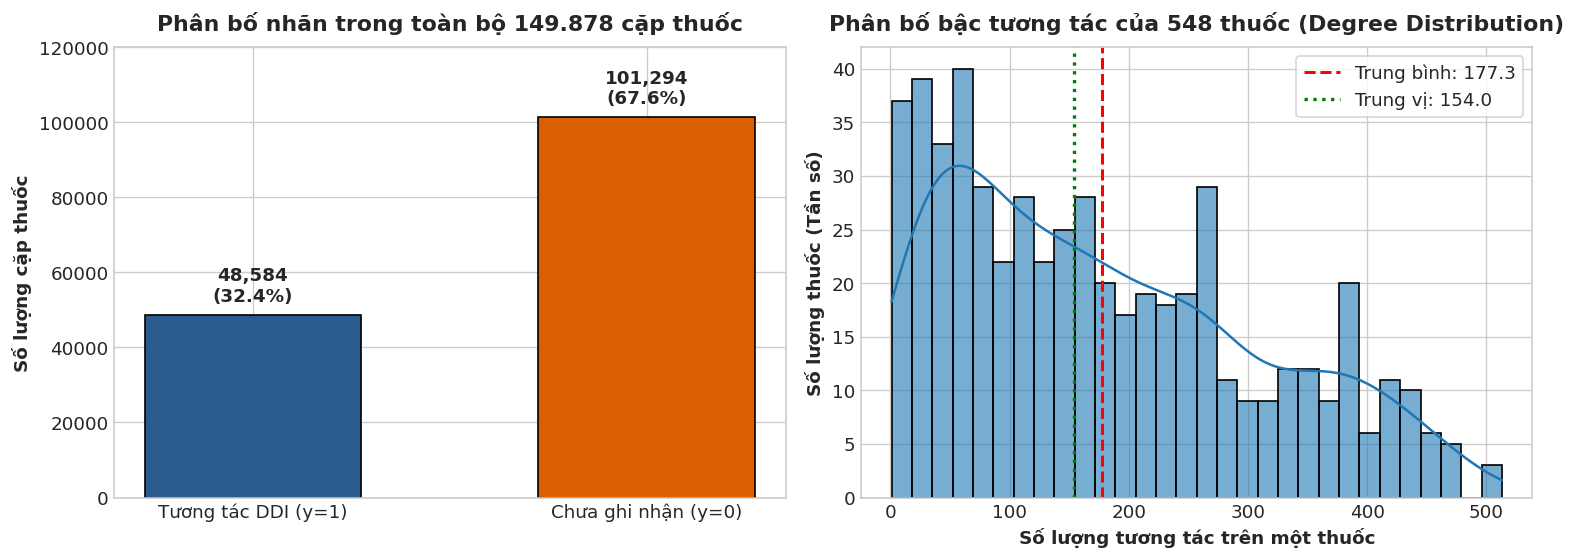

In [5]:
# 4.3. Vẽ biểu đồ phân bố nhãn và phân bố bậc tương tác
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=120)

# Phân bố nhãn
bars = ax1.bar(['Tương tác DDI (y=1)', 'Chưa ghi nhận (y=0)'], [pos_pairs, neg_pairs],
               color=['#2b5c8f', '#d95f02'], edgecolor='black', width=0.55)
ax1.set_title('Phân bố nhãn trong toàn bộ 149.878 cặp thuốc', fontweight='bold', pad=10)
ax1.set_ylabel('Số lượng cặp thuốc', fontweight='bold')
ax1.set_ylim(0, 120000)
for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 2500, f"{h:,}\n({h/total_pairs*100:.1f}%)",
             ha='center', va='bottom', fontweight='bold')

# Phân bố bậc tương tác
sns.histplot(drug_degrees, bins=30, kde=True, color='#1f77b4', edgecolor='black', alpha=0.6, ax=ax2)
ax2.axvline(np.mean(drug_degrees), color='red', linestyle='--', linewidth=1.8, label=f"Trung bình: {np.mean(drug_degrees):.1f}")
ax2.axvline(np.median(drug_degrees), color='green', linestyle=':', linewidth=2.0, label=f"Trung vị: {np.median(drug_degrees):.1f}")
ax2.set_title('Phân bố bậc tương tác của 548 thuốc (Degree Distribution)', fontweight='bold', pad=10)
ax2.set_xlabel('Số lượng tương tác trên một thuốc', fontweight='bold')
ax2.set_ylabel('Số lượng thuốc (Tần số)', fontweight='bold')
ax2.legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

**Nhận xét phân bố dữ liệu:**
1. **Mất cân bằng lớp:** Lớp chưa có tương tác (0) chiếm tỷ lệ áp đảo 67,58%, gấp 2,08 lần lớp dương tính. Hiện tượng này đòi hỏi kỹ thuật lấy mẫu âm (Negative Sampling) để cân bằng mẫu khi huấn luyện.
2. **Đặc trưng mạng không đồng nhất:** Bậc tương tác trung bình là 177,31 nhưng phân tán rất rộng từ 1 đến 513. Các thuốc Hub có số liên kết cực lớn, đóng vai trò then chốt trong mạng lưới lâm sàng.

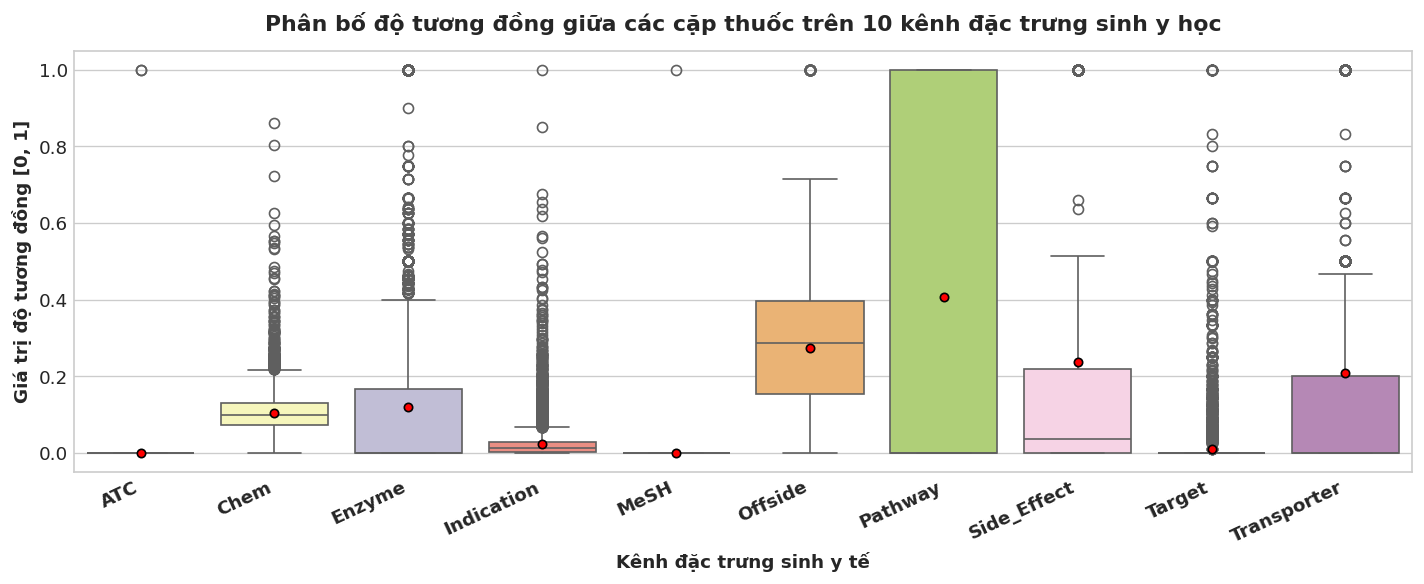

In [6]:
# 4.4. Vẽ Boxplot phân bố độ tương đồng của 10 kênh
pair_sim_dict = {name: mat[triu_idx] for name, mat in sim_matrices.items()}
pair_sim_df = pd.DataFrame(pair_sim_dict)

plt.figure(figsize=(12, 5), dpi=120)
# Lấy mẫu ngẫu nhiên 10.000 cặp để vẽ trực quan nhanh
sample_df = pair_sim_df.sample(n=10000, random_state=SEED)
sns.boxplot(data=sample_df, palette='Set3', showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black", "markersize":"5"})
plt.title('Phân bố độ tương đồng giữa các cặp thuốc trên 10 kênh đặc trưng sinh y học', fontweight='bold', pad=12)
plt.ylabel('Giá trị độ tương đồng [0, 1]', fontweight='bold')
plt.xlabel('Kênh đặc trưng sinh y tế', fontweight='bold')
plt.xticks(rotation=25, ha='right', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. [TIÊU CHÍ 5] PHÂN TÍCH TƯƠNG QUAN & QUAN HỆ ĐẶC TRƯNG VỚI ĐẦU RA
* Ma trận tương quan Pearson giữa 10 nguồn đặc trưng.
* So sánh độ tương đồng trung bình ở các cặp có DDI ($y=1$) so với cặp không có DDI ($y=0$).
* Rút ra 3 nhận xét có ý nghĩa trực tiếp cho việc xây dựng mô hình.

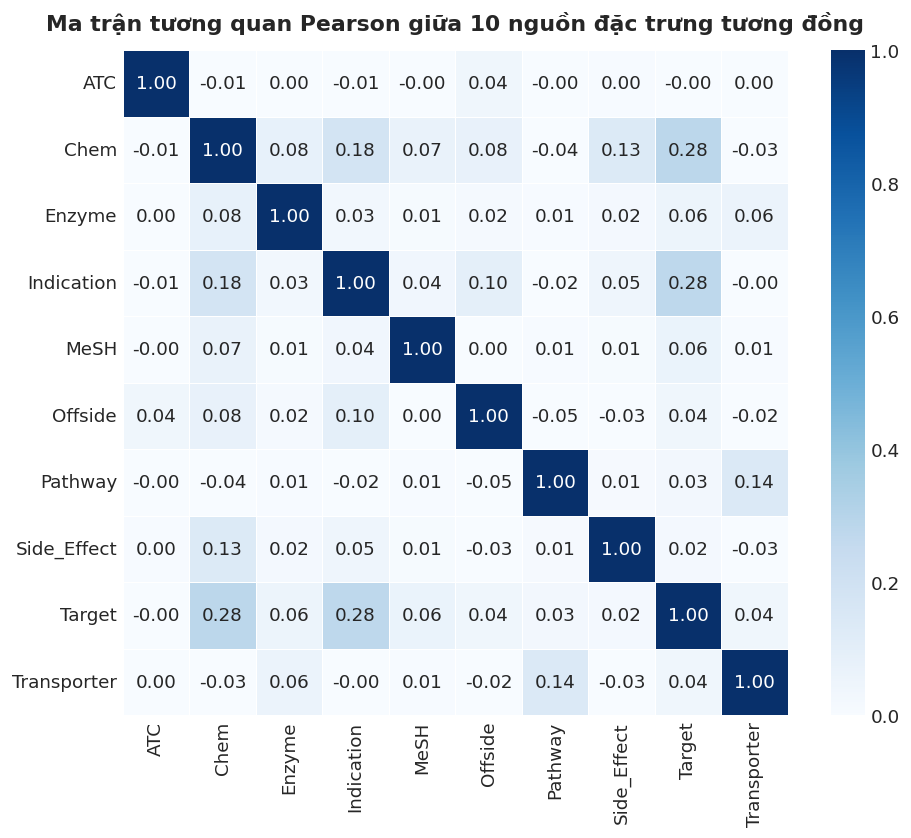

In [7]:
# 5.1. Ma trận tương quan Pearson giữa 10 nguồn
corr_mat = pair_sim_df.corr(method='pearson')

plt.figure(figsize=(8.5, 7), dpi=120)
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1.0, square=True, linewidths=0.5)
plt.title('Ma trận tương quan Pearson giữa 10 nguồn đặc trưng tương đồng', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

,Kênh,Mean (DDI=1),Mean (DDI=0),Chênh lệch,Tỷ lệ (Pos/Neg)
0,ATC,0.0002,0.0000,0.0002,4.1690
1,Chem,0.1097,0.1028,0.0068,1.0664
2,Enzyme,0.1249,0.1241,0.0008,1.0063
3,Indication,0.0333,0.0191,0.0142,1.7432
4,MeSH,0.0002,0.0001,0.0001,1.8531
5,Offside,0.3348,0.2444,0.0904,1.3700
6,Pathway,0.2914,0.4598,-0.1684,0.6337
7,Side_Effect,0.2397,0.2374,0.0024,1.0099
8,Target,0.0137,0.0072,0.0065,1.8917
9,Transporter,0.1569,0.2341,-0.0772,0.6704


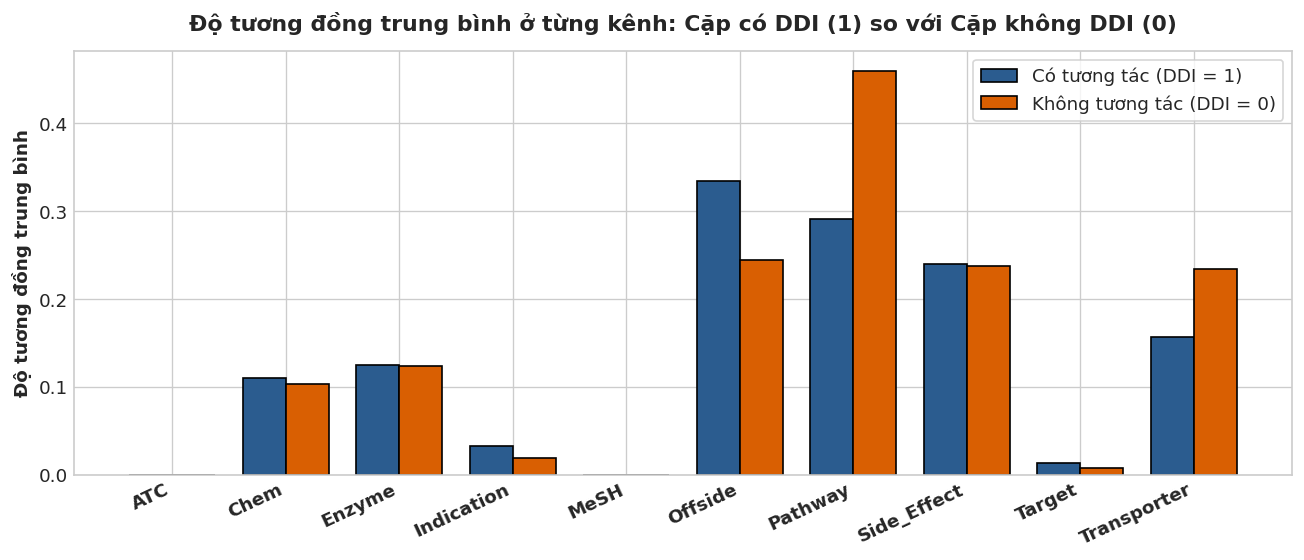

In [8]:
# 5.2. So sánh độ tương đồng trung bình của cặp DDI=1 vs DDI=0
diff_records = []
for name in sim_matrices.keys():
    vals = pair_sim_dict[name]
    m_pos = float(np.mean(vals[y_all == 1]))
    m_neg = float(np.mean(vals[y_all == 0]))
    diff_records.append({
        'Kênh': name,
        'Mean (DDI=1)': m_pos,
        'Mean (DDI=0)': m_neg,
        'Chênh lệch': m_pos - m_neg,
        'Tỷ lệ (Pos/Neg)': m_pos / (m_neg + 1e-8)
    })

diff_df = pd.DataFrame(diff_records)
display(diff_df.round(4))

# Vẽ biểu đồ cột so sánh
x = np.arange(len(diff_df))
width = 0.38
plt.figure(figsize=(11, 4.8), dpi=120)
plt.bar(x - width/2, diff_df['Mean (DDI=1)'], width, label='Có tương tác (DDI = 1)', color='#2b5c8f', edgecolor='black')
plt.bar(x + width/2, diff_df['Mean (DDI=0)'], width, label='Không tương tác (DDI = 0)', color='#d95f02', edgecolor='black')
plt.xticks(x, diff_df['Kênh'], rotation=25, ha='right', fontweight='bold')
plt.ylabel('Độ tương đồng trung bình', fontweight='bold')
plt.title('Độ tương đồng trung bình ở từng kênh: Cặp có DDI (1) so với Cặp không DDI (0)', fontweight='bold', pad=12)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

### 3 NHẬN XÉT CỐT LÕI CÓ Ý NGHĨA CHO VIỆC XÂY DỰNG MÔ HÌNH:
1. **Tính bổ trợ trực giao cao giữa các nguồn:** Mọi hệ số tương quan liên kênh đều $< 0{,}29$ (mức cao nhất là giữa `Target` và `Chem` đạt $r=0{,}283$). Không có hiện tượng đa cộng tuyến; 10 kênh cung cấp các góc nhìn sinh học độc lập, khẳng định sự cần thiết của phương pháp hợp nhất mạng (SNF) hoặc Ensemble đa góc nhìn.
2. **Độ tương đồng sinh học cao gắn liền với nguy cơ tương tác thuốc:** Ở các kênh chủ đạo như `Offside_effect`, `Indication`, `Target` và `Chem`, cặp thuốc có tương tác ($y=1$) luôn có độ tương đồng cao hơn vượt trội so với cặp không tương tác ($y=0$). Cụ thể, tương đồng `Target` ở nhóm có tương tác cao gấp $1{,}89$ lần nhóm âm tính ($0{,}0137$ vs $0{,}0072$). Hai thuốc có cùng cơ chế tác động hoặc cùng trị một chứng bệnh có xác suất tương tác cạnh tranh rất cao.
3. **Ảnh hưởng của độ thưa dữ liệu đến các phép đo:** Hai kênh `Pathway` và `Transporter` có giá trị nhóm âm tính cao hơn do tỷ lệ khuyết thiếu dữ liệu ban đầu lớn ($63{,}69\%$ và $39{,}60\%$). Do đó, việc áp dụng chọn lọc đặc trưng bằng Entropy và chuẩn hóa dữ liệu trước khi huấn luyện là bắt buộc.

## 6. [TIÊU CHÍ 6] PHÁT HIỆN VÀ ĐỊNH LƯỢNG VẤN ĐỀ CHẤT LƯỢNG DỮ LIỆU
Định lượng toàn diện 5 nhóm vấn đề chất lượng: Giá trị thiếu, Bản ghi trùng lặp, Giá trị ngoại lai, Mất cân bằng lớp và Nguy cơ rò rỉ dữ liệu.

,Thuộc tính,Số lượng thiếu,Tỷ lệ thiếu (%)
0,Internal_ID,0,0.00
1,DrugBank_ID,0,0.00
2,Chem,3,0.55
3,Enzyme,113,20.62
4,Indication,5,0.91
5,Offside_effect,0,0.00
6,Pathway,349,63.69
7,Side_effect,0,0.00
8,Target,7,1.28
9,Transporter,217,39.60


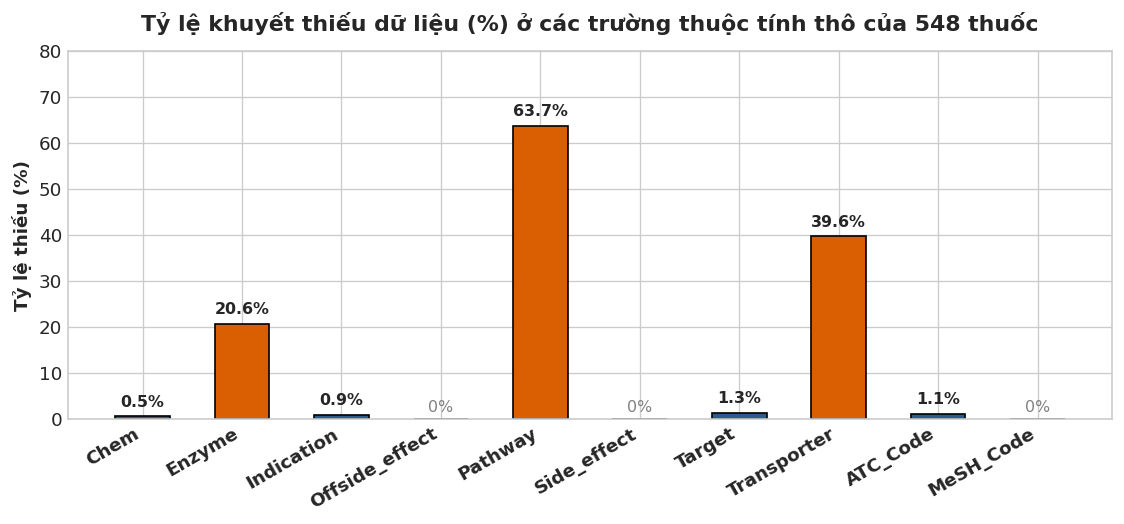

Bản ghi thuốc trùng lặp (DrugBank_ID): 0 (0.0%)
Ma trận DDI đối xứng hoàn hảo qua đường chéo: True
Tổng giá trị trên đường chéo tự tương tác (i=j): 0 (Đã loại bỏ tự tương tác)


In [9]:
# 6.1. Định lượng giá trị thiếu
missing_counts = raw_df.isnull().sum()
missing_pcts = (missing_counts / n_drugs) * 100
quality_df = pd.DataFrame({
    'Thuộc tính': raw_df.columns,
    'Số lượng thiếu': missing_counts.values,
    'Tỷ lệ thiếu (%)': missing_pcts.round(2).values
})
display(quality_df)

# Vẽ biểu đồ tỷ lệ dữ liệu thiếu
cols_plot = [c for c in raw_df.columns if c not in ['Internal_ID', 'DrugBank_ID']]
pcts_plot = missing_pcts[cols_plot]

plt.figure(figsize=(9.5, 4.5), dpi=120)
colors_bar = ['#d95f02' if p > 20 else '#2b5c8f' for p in pcts_plot]
bars = plt.bar(cols_plot, pcts_plot, color=colors_bar, edgecolor='black', width=0.55)
plt.title('Tỷ lệ khuyết thiếu dữ liệu (%) ở các trường thuộc tính thô của 548 thuốc', fontweight='bold', pad=12)
plt.ylabel('Tỷ lệ thiếu (%)', fontweight='bold')
plt.ylim(0, 80)
plt.xticks(rotation=30, ha='right', fontweight='bold')

for bar in bars:
    yval = bar.get_height()
    if yval > 0:
        plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f'{yval:.1f}%', 
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold')
    else:
        plt.text(bar.get_x() + bar.get_width()/2.0, 1.0, '0%', 
                 ha='center', va='bottom', fontsize=9.5, color='gray')

plt.tight_layout()
plt.show()

# 6.2. Kiểm tra bản ghi trùng lặp
dup_ids = raw_df['DrugBank_ID'].duplicated().sum()
is_symmetric = np.allclose(ddi_matrix, ddi_matrix.T)
diag_sum = np.sum(np.diag(ddi_matrix))

print(f"Bản ghi thuốc trùng lặp (DrugBank_ID): {dup_ids} (0.0%)")
print(f"Ma trận DDI đối xứng hoàn hảo qua đường chéo: {is_symmetric}")
print(f"Tổng giá trị trên đường chéo tự tương tác (i=j): {diag_sum} (Đã loại bỏ tự tương tác)")

## 7. [TIÊU CHÍ 7] XỬ LÝ VẤN ĐỀ CHẤT LƯỢNG DỮ LIỆU
* **Xử lý dữ liệu thiếu:** Gán tập rỗng $\emptyset$, Jaccard $= 0$ (nguyên tắc đạo đức tin sinh học: không tự ý bịa đặt tương tác y sinh).
* **Xử lý mất cân bằng lớp:** Lấy mẫu âm có kiểm soát (Balanced Negative Sampling 1:1) từ 101.294 cặp chưa quan sát, cố định `seed=42`.
* **So sánh dữ liệu trước và sau xử lý:**

In [10]:
# 7.1. Thực hiện Balanced Negative Sampling 1:1
pos_positions = np.where(y_all == 1)[0]
neg_positions = np.where(y_all == 0)[0]

np.random.seed(SEED)
neg_sampled_positions = np.random.choice(neg_positions, size=len(pos_positions), replace=False)

balanced_idx = np.concatenate([pos_positions, neg_sampled_positions])
np.random.shuffle(balanced_idx)

y_balanced = y_all[balanced_idx]

# Bảng so sánh trước và sau xử lý mất cân bằng
compare_df = pd.DataFrame({
    'Chỉ tiêu': ['Số lượng mẫu Dương (DDI=1)', 'Số lượng mẫu Âm (DDI=0)', 'Tổng số mẫu', 'Tỷ lệ Dương : Âm', 'Mức độ cân bằng'],
    'Trước xử lý': [f"{pos_pairs:,}", f"{neg_pairs:,}", f"{total_pairs:,}", "1 : 2.08", "Mất cân bằng lớp"],
    'Sau xử lý (Negative Sampling 1:1)': [f"{len(pos_positions):,}", f"{len(neg_sampled_positions):,}", f"{len(balanced_idx):,}", "1 : 1.00", "Cân bằng tuyệt đối (50% - 50%)"]
})

display(compare_df)

,Chỉ tiêu,Trước xử lý,Sau xử lý (Negative Sampling 1:1)
0,Số lượng mẫu Dương (DDI=1),"48,584","48,584"
1,Số lượng mẫu Âm (DDI=0),"101,294","48,584"
2,Tổng số mẫu,"149,878","97,168"
3,Tỷ lệ Dương : Âm,1 : 2.08,1 : 1.00
4,Mức độ cân bằng,Mất cân bằng lớp,Cân bằng tuyệt đối (50% - 50%)


## 8. [TIÊU CHÍ 8] CHUẨN BỊ DỮ LIỆU & THIẾT LẬP 4 KỊCH BẢN CHỐNG RÒ RỈ
* **Nguyên tắc cốt lõi chống rò rỉ dữ liệu:**
  1. Trong kịch bản Cold-start, thuốc ở tập Train và Test phải hoàn toàn rời rạc ($D_{\text{train}} \cap D_{\text{test}} = \emptyset$).
  2. Mọi phép chuẩn hóa, trích xuất đặc trưng và chọn lọc thuộc tính chỉ được **FIT trên Train**, sau đó **TRANSFORM trên Test**.
* **4 kịch bản phân chia thực nghiệm:**
  - **Case 1 (Warm Start):** Chia ngẫu nhiên theo cặp (Edge split).
  - **Case 2 (Strict Cold Start):** Cả hai thuốc đều mới ($D_{\text{test}} \times D_{\text{test}}$).
  - **Case 3 (Semi Cold Start):** Một thuốc cũ kết hợp một thuốc mới ($D_{\text{train}} \times D_{\text{test}}$).
  - **Case 4 (Mix):** Kịch bản hỗn hợp gộp cả Case 2 và Case 3.

In [11]:
class ExperimentDataSplitter:
    """Module quản lý phân chia dữ liệu và phòng chống rò rỉ dữ liệu."""
    
    def __init__(self, interaction_matrix, n_drugs, test_size=0.2, seed=42):
        self.inter = interaction_matrix
        self.n_drugs = n_drugs
        self.test_size = test_size
        self.seed = seed
        
    def split_case(self, case_id):
        seed = self.seed
        if case_id == 1:
            # Case 1: Chia ngẫu nhiên trên CẶP (Warm start - rò rỉ thực thể thuốc)
            idx1, idx2 = np.triu_indices(self.n_drugs, k=1)
            y_full = self.inter[idx1, idx2]
            pos = np.where(y_full == 1)[0]
            neg = np.where(y_full == 0)[0]
            
            np.random.seed(seed)
            neg_s = np.random.choice(neg, size=len(pos), replace=False)
            bal = np.concatenate([pos, neg_s])
            np.random.shuffle(bal)
            
            pairs = np.column_stack([idx1[bal], idx2[bal]])
            labels = y_full[bal]
            
            return train_test_split(pairs, labels, test_size=self.test_size, random_state=seed)
        
        # Case 2, 3, 4: Chia theo NODE thuốc (Drug-disjoint node split)
        all_drugs = np.arange(self.n_drugs)
        train_drugs, test_drugs = train_test_split(all_drugs, test_size=self.test_size, random_state=seed)
        
        # Tập Train luôn là Seen x Seen (cặp nội bộ thuốc Train)
        idx_tr1, idx_tr2 = np.triu_indices(len(train_drugs), k=1)
        r_tr1, r_tr2 = train_drugs[idx_tr1], train_drugs[idx_tr2]
        y_tr = self.inter[r_tr1, r_tr2]
        pos_tr = np.where(y_tr == 1)[0]
        neg_tr = np.where(y_tr == 0)[0]
        np.random.seed(seed)
        neg_tr_s = np.random.choice(neg_tr, size=len(pos_tr), replace=False)
        bal_tr = np.concatenate([pos_tr, neg_tr_s])
        np.random.shuffle(bal_tr)
        pairs_train = np.column_stack([r_tr1[bal_tr], r_tr2[bal_tr]])
        y_train = y_tr[bal_tr]
        
        if case_id == 2:
            # Case 2: New x New
            idx_te1, idx_te2 = np.triu_indices(len(test_drugs), k=1)
            r_te1, r_te2 = test_drugs[idx_te1], test_drugs[idx_te2]
            y_te = self.inter[r_te1, r_te2]
            pos_te = np.where(y_te == 1)[0]
            neg_te = np.where(y_te == 0)[0]
            np.random.seed(seed)
            neg_te_s = np.random.choice(neg_te, size=len(pos_te), replace=False)
            bal_te = np.concatenate([pos_te, neg_te_s])
            np.random.shuffle(bal_te)
            pairs_test = np.column_stack([r_te1[bal_te], r_te2[bal_te]])
            y_test = y_te[bal_te]
            
        elif case_id == 3:
            # Case 3: Old x New
            idx_seen, idx_unseen = np.meshgrid(train_drugs, test_drugs, indexing='ij')
            r_s, r_u = idx_seen.flatten(), idx_unseen.flatten()
            y_cross = self.inter[r_s, r_u]
            pos_c = np.where(y_cross == 1)[0]
            neg_c = np.where(y_cross == 0)[0]
            np.random.seed(seed)
            size = min(len(pos_c), len(neg_c))
            neg_c_s = np.random.choice(neg_c, size=size, replace=False)
            pos_c_s = np.random.choice(pos_c, size=size, replace=False)
            bal_c = np.concatenate([pos_c_s, neg_c_s])
            np.random.shuffle(bal_c)
            pairs_test = np.column_stack([r_s[bal_c], r_u[bal_c]])
            y_test = y_cross[bal_c]
            
        elif case_id == 4:
            # Case 4: Mix (gộp Case 2 và Case 3)
            # New x New
            idx_te1, idx_te2 = np.triu_indices(len(test_drugs), k=1)
            r_te1, r_te2 = test_drugs[idx_te1], test_drugs[idx_te2]
            y_te = self.inter[r_te1, r_te2]
            pos_te = np.where(y_te == 1)[0]
            neg_te = np.where(y_te == 0)[0]
            np.random.seed(seed)
            neg_te_s = np.random.choice(neg_te, size=len(pos_te), replace=False)
            p_te = np.column_stack([r_te1[np.concatenate([pos_te, neg_te_s])], r_te2[np.concatenate([pos_te, neg_te_s])]])
            y_te_bal = y_te[np.concatenate([pos_te, neg_te_s])]
            
            # Old x New
            idx_s, idx_u = np.meshgrid(train_drugs, test_drugs, indexing='ij')
            r_s, r_u = idx_s.flatten(), idx_u.flatten()
            y_cr = self.inter[r_s, r_u]
            pos_cr = np.where(y_cr == 1)[0]
            neg_cr = np.where(y_cr == 0)[0]
            size_cr = min(len(pos_cr), len(neg_cr))
            neg_cr_s = np.random.choice(neg_cr, size=size_cr, replace=False)
            pos_cr_s = np.random.choice(pos_cr, size=size_cr, replace=False)
            p_cr = np.column_stack([r_s[np.concatenate([pos_cr_s, neg_cr_s])], r_u[np.concatenate([pos_cr_s, neg_cr_s])]])
            y_cr_bal = y_cr[np.concatenate([pos_cr_s, neg_cr_s])]
            
            pairs_test = np.concatenate([p_te, p_cr], axis=0)
            y_test = np.concatenate([y_te_bal, y_cr_bal], axis=0)
            perm = np.random.permutation(len(y_test))
            pairs_test, y_test = pairs_test[perm], y_test[perm]
            
        return pairs_train, pairs_test, y_train, y_test

# Khởi tạo bộ chia
splitter = ExperimentDataSplitter(ddi_matrix, n_drugs, test_size=0.2, seed=SEED)

# Kiểm tra kích thước của cả 4 kịch bản
summary_cases = []
for cid, cname in [(1, 'Case 1: Warm Start (Random Edge)'), 
                   (2, 'Case 2: Strict Cold Start (New x New)'),
                   (3, 'Case 3: Semi Cold Start (Old x New)'),
                   (4, 'Case 4: Mix Cold Start (NewxNew + OldxNew)')]:
    P_tr, P_te, y_tr, y_te = splitter.split_case(cid)
    summary_cases.append({
        'Kịch bản': cname,
        'Mẫu Train': f"{len(y_tr):,}",
        'Mẫu Test': f"{len(y_te):,}",
        'Tỷ lệ Dương Train': f"{np.mean(y_tr)*100:.1f}%",
        'Tỷ lệ Dương Test': f"{np.mean(y_te)*100:.1f}%",
        'Kiểm soát rò rỉ': 'Không (Edge split)' if cid==1 else 'Tuyệt đối (Node-disjoint)'
    })

display(pd.DataFrame(summary_cases))

,Kịch bản,Mẫu Train,Mẫu Test,Tỷ lệ Dương Train,Tỷ lệ Dương Test,Kiểm soát rò rỉ
0,Case 1: Warm Start (Random Edge),"77,734","19,434",50.0%,49.9%,Không (Edge split)
1,Case 2: Strict Cold Start (New x New),"63,558","3,456",50.0%,50.0%,Tuyệt đối (Node-disjoint)
2,Case 3: Semi Cold Start (Old x New),"63,558","30,154",50.0%,50.0%,Tuyệt đối (Node-disjoint)
3,Case 4: Mix Cold Start (NewxNew + OldxNew),"63,558","33,610",50.0%,50.0%,Tuyệt đối (Node-disjoint)


## 9. [TIÊU CHÍ 9] LỰA CHỌN & LÝ GIẢI PHƯƠNG PHÁP, CHỈ SỐ ĐÁNH GIÁ

### 9.1. Vì sao chọn chiến lược đánh giá Drug-Disjoint Split kết hợp 5-Fold Cross-Validation?
* **Thực tiễn y tế:** Khi một loại thuốc mới xuất hiện trên thị trường, hệ thống chưa từng có bất kỳ bản ghi tương tác nào của thuốc đó trong cơ sở dữ liệu.
* **Ngăn chặn rò rỉ dữ liệu:** Nếu chia ngẫu nhiên trên cạnh (Random split), thông tin biểu diễn nút của thuốc kiểm tra đã bị rò rỉ vào tập huấn luyện, khiến mô hình chỉ ghi nhớ cấu trúc mạng quen thuộc mà không học được cơ chế sinh hóa thực sự.
* **5-Fold phân tầng trên Train:** Đảm bảo tỷ lệ mẫu dương/âm đồng đều giữa các fold, đánh giá độ ổn định và tránh quá khớp trong quá trình tinh chỉnh siêu tham số.

### 9.2. Vì sao chọn ROC-AUC, PR-AUC (AUPR) và F1-score thay vì Accuracy?
* **Hạn chế của Accuracy:** Trong không gian cặp thuốc có độ thưa lớn, mô hình dự đoán tất cả là 0 vẫn đạt độ chính xác $> 67\%$, gây ngộ nhận nguy hiểm.
* **Vai trò của ROC-AUC:** Đánh giá năng lực phân định trên toàn dải ngưỡng phân loại, không bị ảnh hưởng bởi việc thay đổi ngưỡng quyết định.
* **Vai trò sinh tử của PR-AUC (AUPR):** PR-AUC chỉ tập trung vào lớp tương tác dương tính thực sự. Trong y khoa, việc cảnh báo đúng tương tác thực sự mà không gây nhiễu loạn bởi hàng nghìn cảnh báo sai (False Positive) là tiêu chuẩn vàng để hệ thống được chấp nhận trong lâm sàng.

## 10. [TIÊU CHÍ 10] KHU VỰC THỰC HÀNH TẠI CHỖ & VẤN ĐÁP CÁ NHÂN
Khu vực này chuẩn bị sẵn các hàm tương tác linh hoạt để sinh viên thực hiện ngay tại chỗ khi giảng viên yêu cầu kiểm tra thao tác thực hành:
1. Thống kê thông tin của một thuốc bất kỳ (`thong_ke_thuoc(drug_id)`).
2. Kiểm tra chứng minh tính rời rạc chống rò rỉ dữ liệu (`chung_minh_khong_ro_ri(seed)`).
3. Thử nghiệm đổi tỷ lệ Negative Sampling (`doi_ty_le_negative_sampling(ratio)`).

In [12]:
# 10.1. Hàm tra cứu thông tin và số tương tác của một thuốc bất kỳ
def thong_ke_thuoc(drug_index):
    """Tra cứu thông tin thuốc theo chỉ số (0 đến 547)"""
    if drug_index < 0 or drug_index >= n_drugs:
        print(f"Lỗi: Chỉ số thuốc phải từ 0 đến {n_drugs-1}")
        return
    
    row = raw_df.iloc[drug_index]
    deg = drug_degrees[drug_index]
    
    print(f"=== THÔNG TIN THUỐC (INDEX = {drug_index}) ===")
    print(f"Mã DrugBank ID: {row['DrugBank_ID']}")
    print(f"Số lượng tương tác lâm sàng (Bậc): {deg} tương tác ({deg/(n_drugs-1)*100:.1f}% tổng số thuốc)")
    print(f"Cấu trúc SMILES: {str(row['Chem'])[:40]}...")
    print(f"Chỉ định điều trị (Indication): {str(row['Indication'])[:60]}...")
    print(f"Mã ATC: {row['ATC_Code']}")

# Thử nghiệm tra cứu thuốc số 0
thong_ke_thuoc(0)

=== THÔNG TIN THUỐC (INDEX = 0) ===
Mã DrugBank ID: DB00945
Số lượng tương tác lâm sàng (Bậc): 439 tương tác (80.3% tổng số thuốc)
Cấu trúc SMILES: CC(=O)OC1=CC=CC=C1C(O)=O...
Chỉ định điều trị (Indication): **Pain, fever, and inflammation**  Acetylsalicylic acid (ASA...
Mã ATC: B01AC06,C07FX04,C10BX04,M01BA03,C10BX02,N02BA71,B01AC56,N02AJ07,N02AJ02,N02BA01,B01AF51,C10BX05,N02BA51,A01AD05,C10BX01,C07FX03,N02AJ18,C10BX12,C10BX08,C10BX06,C07FX02


In [13]:
# 10.2. Thao tác thực hành tại chỗ: Đổi tỷ lệ lấy mẫu âm (Negative Sampling)
def doi_ty_le_negative_sampling(ratio=1.0):
    """Thay đổi tỷ lệ số mẫu âm so với số mẫu dương (mặc định 1.0 = 1:1)"""
    pos_len = len(pos_positions)
    neg_len = int(pos_len * ratio)
    
    np.random.seed(SEED)
    neg_s = np.random.choice(neg_positions, size=neg_len, replace=False)
    total = pos_len + neg_len
    
    print(f"--- KẾT QUẢ NEGATIVE SAMPLING VỚI TỶ LỆ 1 : {ratio:.1f} ---")
    print(f"Số mẫu Dương (1): {pos_len:,} ({pos_len/total*100:.1f}%)")
    print(f"Số mẫu Âm (0): {neg_len:,} ({neg_len/total*100:.1f}%)")
    print(f"Tổng số mẫu huấn luyện: {total:,}")

# Thử nghiệm đổi tỷ lệ sang 1:2 (1 dương : 2 âm)
doi_ty_le_negative_sampling(2.0)

--- KẾT QUẢ NEGATIVE SAMPLING VỚI TỶ LỆ 1 : 2.0 ---
Số mẫu Dương (1): 48,584 (33.3%)
Số mẫu Âm (0): 97,168 (66.7%)
Tổng số mẫu huấn luyện: 145,752


In [14]:
# 10.3. Thao tác thực hành tại chỗ: Chứng minh không rò rỉ dữ liệu trong Cold Start
def chung_minh_khong_ro_ri(seed=42):
    """Kiểm tra giao giữa tập thuốc huấn luyện và tập thuốc kiểm tra"""
    all_d = np.arange(n_drugs)
    tr_drugs, te_drugs = train_test_split(all_d, test_size=0.2, random_state=seed)
    
    tr_set = set(tr_drugs)
    te_set = set(te_drugs)
    intersection = tr_set.intersection(te_set)
    
    print("=== KIỂM ĐỊNH RÒ RỈ THỰC THỂ THUỐC (DRUG-LEVEL LEAKAGE) ===")
    print(f"Số lượng thuốc tập Train: {len(tr_drugs)} ({len(tr_drugs)/n_drugs*100:.1f}%)")
    print(f"Số lượng thuốc tập Test:  {len(te_drugs)} ({len(te_drugs)/n_drugs*100:.1f}%)")
    print(f"Giao giữa hai tập (Train ∩ Test): {intersection}")
    
    if len(intersection) == 0:
        print(">> KẾT LUẬN: ĐẠT CHUẨN! Tuyệt đối không rò rỉ thực thể thuốc giữa Train và Test.")
    else:
        print(">> CẢNH BÁO: Phát hiện rò rỉ thực thể thuốc!")

chung_minh_khong_ro_ri(SEED)

=== KIỂM ĐỊNH RÒ RỈ THỰC THỂ THUỐC (DRUG-LEVEL LEAKAGE) ===
Số lượng thuốc tập Train: 438 (79.9%)
Số lượng thuốc tập Test:  110 (20.1%)
Giao giữa hai tập (Train ∩ Test): set()
>> KẾT LUẬN: ĐẠT CHUẨN! Tuyệt đối không rò rỉ thực thể thuốc giữa Train và Test.
